# 01 - Data acquisition, cleaning and EDA
Heart Disease (Cleveland / UCI) - 13 clinical features + binary target.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
from heart import config, data
from heart import eda
plt.switch_backend('module://matplotlib_inline.backend_inline')  # heart.* forces Agg for CLI/CI; restore inline

## 1. Acquire the data
`scripts/download_data.py` fetches the CSV (see README for the official UCI route). The file is already committed in `data/raw/`, so this notebook works offline.

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
pd.Series(config.DATA_DICTIONARY, name='meaning').to_frame()

,meaning
age,Age in years
sex,"1 = male, 0 = female"
cp,Chest pain type (0-3)
trestbps,Resting blood pressure (mm Hg)
chol,Serum cholesterol (mg/dl)
fbs,Fasting blood sugar > 120 mg/dl (1 = true)
restecg,Resting ECG result (0-2)
thalach,Maximum heart rate achieved
exang,Exercise-induced angina (1 = yes)
oldpeak,ST depression induced by exercise relative to ...


## 2. Quality checks on the raw file

In [4]:
print('duplicates:', raw.duplicated().sum())
print('NaN cells:', int(raw.isna().sum().sum()))
print('ca value counts   :', raw.ca.value_counts().sort_index().to_dict())
print('thal value counts :', raw.thal.value_counts().sort_index().to_dict())
print('target value counts:', raw.target.value_counts().to_dict())

duplicates: 1
NaN cells: 0
ca value counts   : {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thal value counts : {0: 2, 1: 18, 2: 166, 3: 117}
target value counts: {1: 165, 0: 138}


**Findings**
* `ca` has 5 rows coded `4` and `thal` has 2 rows coded `0` - both outside the data dictionary; these are placeholders for *missing*.
* One exact duplicate row.
* In this public mirror `target == 1` means **no disease**. Check: patients with `target == 1` have a *higher* maximum heart rate and *less* exercise angina - the opposite of what disease would cause. The counts (164 healthy / 139 diseased in the original) also match the inverted label. `clean()` therefore flips it so that **1 = disease present**.

In [5]:
print(raw.groupby('target')[['thalach','exang','oldpeak','ca']].mean().round(2))

        thalach  exang  oldpeak    ca
target                               
0        139.10   0.55     1.59  1.17
1        158.47   0.14     0.58  0.36


## 3. Clean

In [6]:
df = data.prepare()
print(df.shape)
print('missing per column:', df.isna().sum()[df.isna().sum() > 0].to_dict())
df.describe().T.round(2)

(302, 14)
missing per column: {'ca': 4, 'thal': 2}


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.96,1.03,0.0,0.00,1.0,2.00,3.0
fbs,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.53,0.53,0.0,0.00,1.0,1.00,2.0
exang,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0


Missing values (6 cells) are **not** filled here. They are imputed inside the model pipeline (median / most-frequent), so the statistics come only from training folds and nothing leaks into validation data.

## 4. Class balance

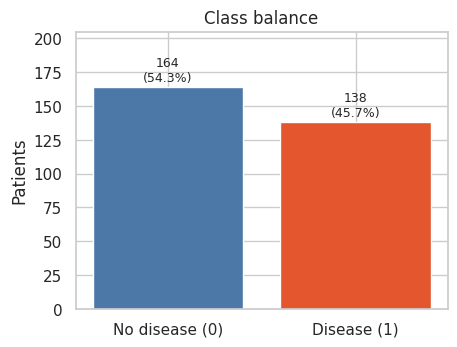

In [7]:
eda.class_balance(df); plt.show()

Classes are nearly balanced (54% / 46%), so accuracy is meaningful, but we still report precision, recall and ROC-AUC.

## 5. Distributions

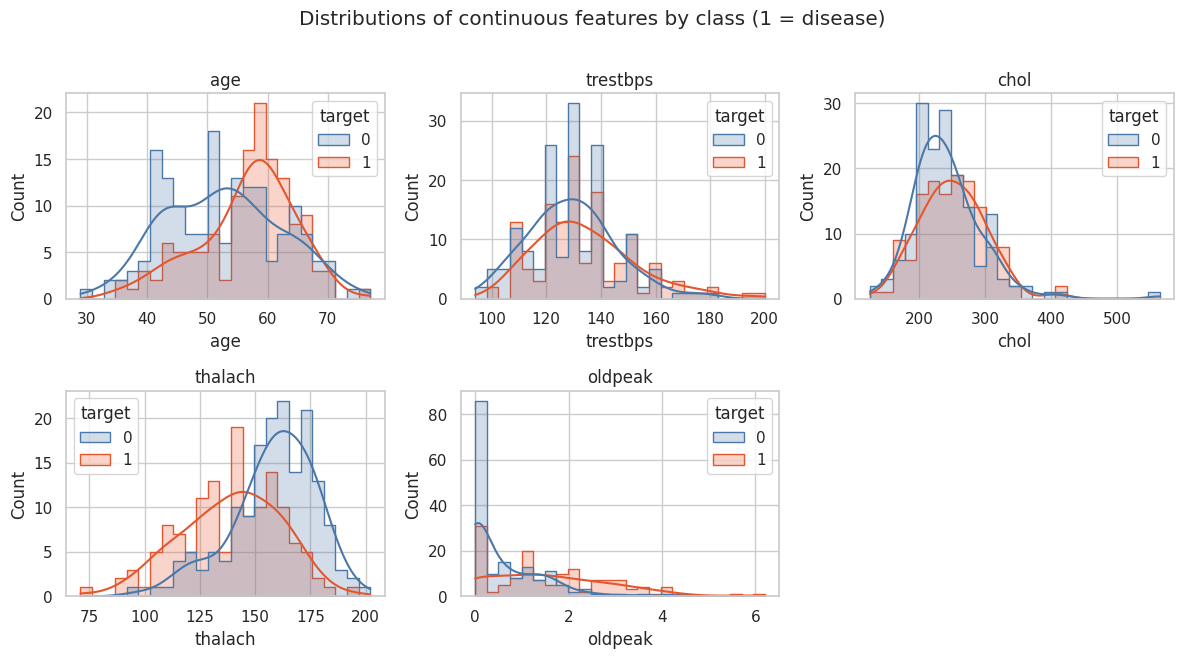

In [8]:
eda.histograms(df); plt.show()

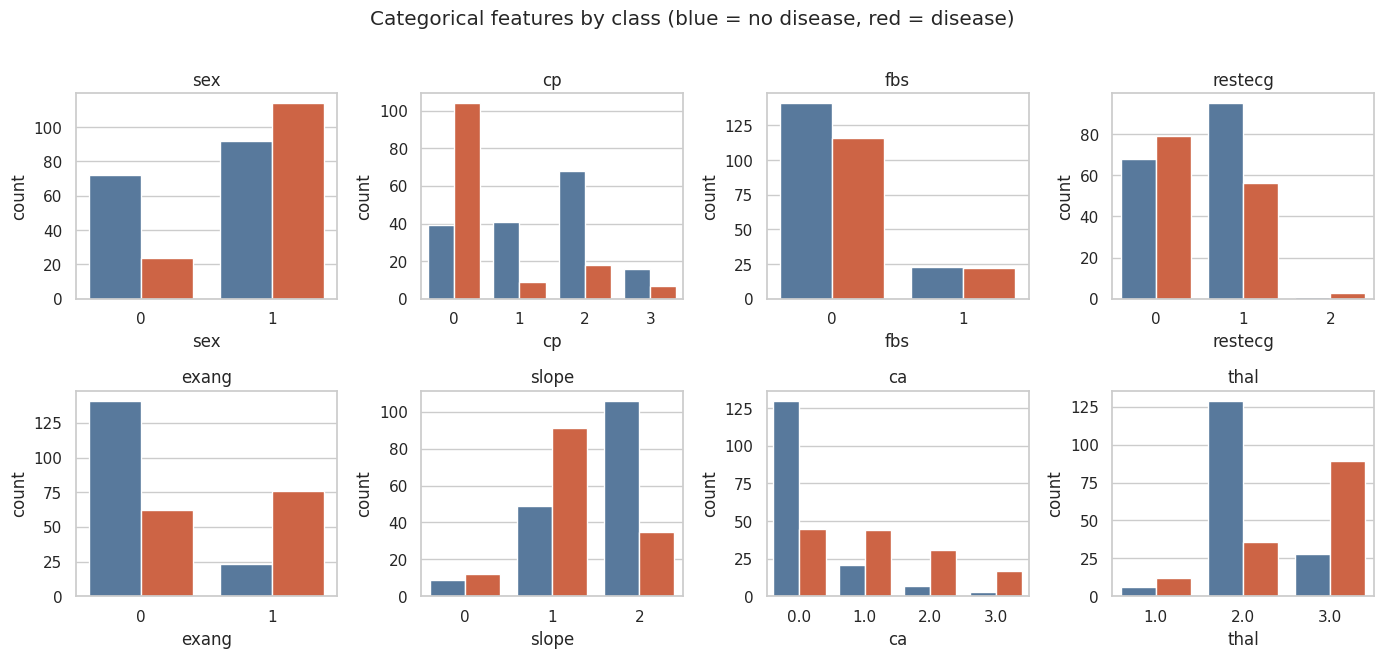

In [9]:
eda.categorical_counts(df); plt.show()

* Disease cases are older, reach a lower maximum heart rate (`thalach`) and have larger ST depression (`oldpeak`).
* Strong categorical signals: `cp = 0` (47% of patients; 73% of them have disease vs 18-30% for the other codes), `exang = 1` (77% vs 31%), `ca >= 1` (68-85% vs 26%) and `thal` 1 or 3 (67-76% vs 22% for code 2).

## 6. Correlations

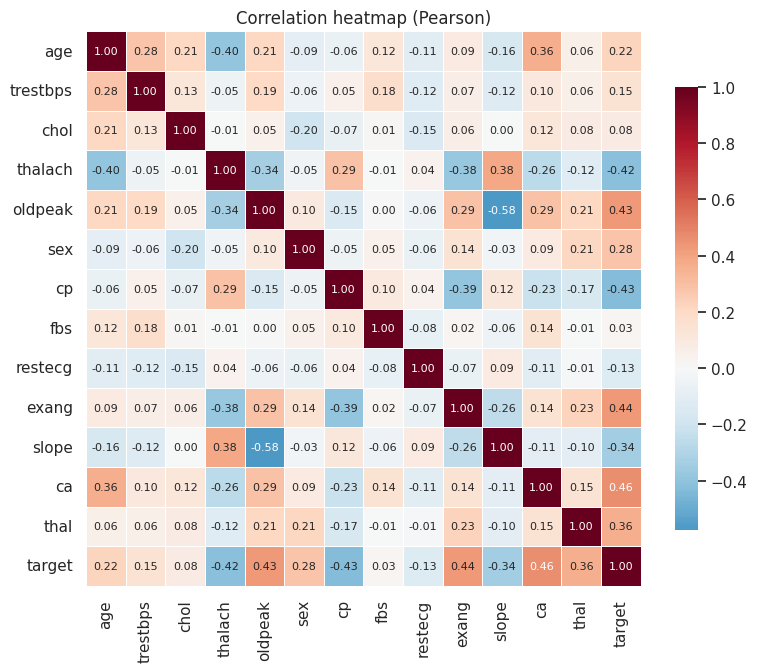

In [10]:
eda.correlation_heatmap(df); plt.show()

In [11]:
df.corr()['target'].drop('target').sort_values(key=abs, ascending=False).round(3).to_frame('corr_with_target')

,corr_with_target
ca,0.464
exang,0.436
cp,-0.432
oldpeak,0.429
thalach,-0.420
thal,0.364
slope,-0.344
sex,0.284
age,0.221
trestbps,0.146


Strongest correlations with the target: `ca` (+0.46), `exang` (+0.44), `cp` (-0.43), `oldpeak` (+0.43), `thalach` (-0.42). No pair of predictors is extremely collinear (max |r| = 0.58, `oldpeak` vs `slope`), so no feature needs to be dropped.

## 7. Outliers

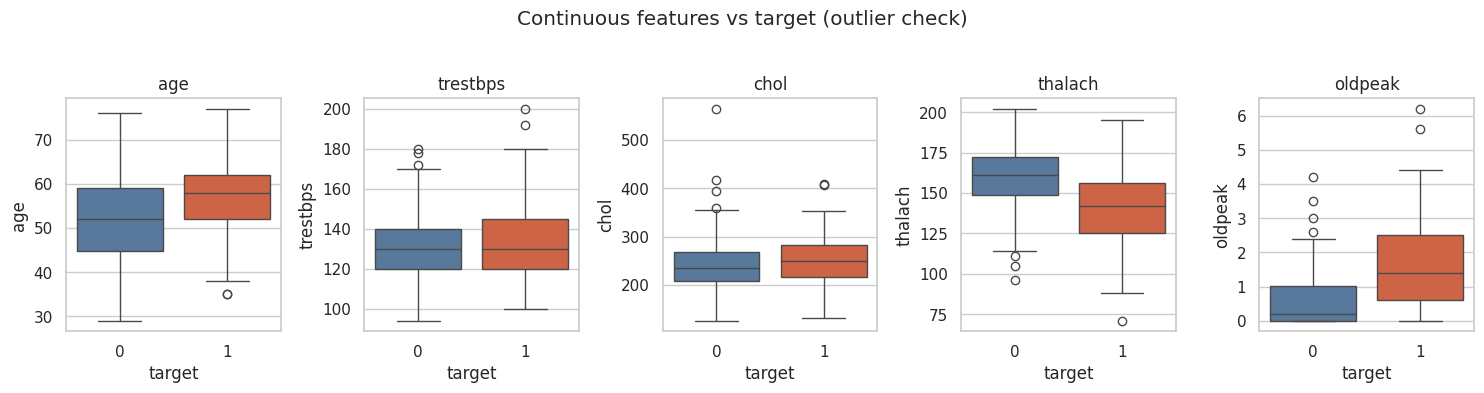

In [12]:
eda.boxplots(df); plt.show()

A few high cholesterol readings (> 400 mg/dl) and `oldpeak` values above 5 exist but are clinically plausible, so they are kept. Standard scaling plus tree-based models are tolerant to them.

In [13]:
eda.run_all(df)  # also writes every figure to reports/figures/ for the report
sorted(p.name for p in config.FIGURES_DIR.glob('*.png'))

['boxplots.png',
 'categorical_counts.png',
 'class_balance.png',
 'correlation_heatmap.png',
 'histograms.png',
 'missing_values.png']